In [1]:
import os
import pandas as pd

CSV_YOLU = "data/glass.csv"
URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/glass/glass.data"
SUTUNLAR = ["id", "RI", "Na", "Mg", "Al", "Si", "K", "Ca", "Ba", "Fe", "tur"]

if not os.path.exists(CSV_YOLU):
    os.makedirs("data", exist_ok=True)
    pd.read_csv(URL, header=None, names=SUTUNLAR).to_csv(CSV_YOLU, index=False)
    print("Veri seti indirildi ve CSV olarak kaydedildi.")
else:
    print("Veri seti mevcut:", CSV_YOLU)

Veri seti mevcut: data/glass.csv


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from matplotlib.colors import ListedColormap

from sklearn.model_selection import (train_test_split, StratifiedKFold, cross_validate,
                                     cross_val_predict, learning_curve)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, classification_report,
                             accuracy_score, balanced_accuracy_score, f1_score, precision_score, recall_score,
                             roc_auc_score, roc_curve, auc, precision_recall_curve, average_precision_score,
                             matthews_corrcoef, cohen_kappa_score, log_loss, top_k_accuracy_score)

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.4f}".format)
sns.set_theme(style="whitegrid", palette="Set2")
%matplotlib inline

df = pd.read_csv(CSV_YOLU)
print("Veri seti başarıyla yüklendi.")
df.head(10)

Veri seti başarıyla yüklendi.


,id,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe,tur
0,1,1.5210,13.6400,4.4900,1.1000,71.7800,0.0600,8.7500,0.0000,0.0000,1
1,2,1.5176,13.8900,3.6000,1.3600,72.7300,0.4800,7.8300,0.0000,0.0000,1
2,3,1.5162,13.5300,3.5500,1.5400,72.9900,0.3900,7.7800,0.0000,0.0000,1
3,4,1.5177,13.2100,3.6900,1.2900,72.6100,0.5700,8.2200,0.0000,0.0000,1
4,5,1.5174,13.2700,3.6200,1.2400,73.0800,0.5500,8.0700,0.0000,0.0000,1
5,6,1.5160,12.7900,3.6100,1.6200,72.9700,0.6400,8.0700,0.0000,0.2600,1
6,7,1.5174,13.3000,3.6000,1.1400,73.0900,0.5800,8.1700,0.0000,0.0000,1
7,8,1.5176,13.1500,3.6100,1.0500,73.2400,0.5700,8.2400,0.0000,0.0000,1
8,9,1.5192,14.0400,3.5800,1.3700,72.0800,0.5600,8.3000,0.0000,0.0000,1
9,10,1.5175,13.0000,3.6000,1.3600,72.9900,0.5700,8.4000,0.0000,0.1100,1


In [3]:
df.tail()

,id,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe,tur
209,210,1.5162,14.1400,0.0000,2.8800,72.6100,0.0800,9.1800,1.0600,0.0000,7
210,211,1.5169,14.9200,0.0000,1.9900,73.0600,0.0000,8.4000,1.5900,0.0000,7
211,212,1.5207,14.3600,0.0000,2.0200,73.4200,0.0000,8.4400,1.6400,0.0000,7
212,213,1.5165,14.3800,0.0000,1.9400,73.6100,0.0000,8.4800,1.5700,0.0000,7
213,214,1.5171,14.2300,0.0000,2.0800,73.3600,0.0000,8.6200,1.6700,0.0000,7


In [4]:
OZELLIKLER = ["RI", "Na", "Mg", "Al", "Si", "K", "Ca", "Ba", "Fe"]
TUR_ADI = {1: "Bina (float)", 2: "Bina (float değil)", 3: "Araç (float)", 5: "Kap", 6: "Sofra", 7: "Far"}

print(f"Gözlem sayısı  : {df.shape[0]}")
print(f"Değişken sayısı: {df.shape[1]} (id + {len(OZELLIKLER)} özellik + hedef)")
print(f"Toplam eksik   : {df.isna().sum().sum()}")
print()
df.info()

Gözlem sayısı  : 214
Değişken sayısı: 11 (id + 9 özellik + hedef)
Toplam eksik   : 0

<class 'pandas.DataFrame'>
RangeIndex: 214 entries, 0 to 213
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   id      214 non-null    int64  
 1   RI      214 non-null    float64
 2   Na      214 non-null    float64
 3   Mg      214 non-null    float64
 4   Al      214 non-null    float64
 5   Si      214 non-null    float64
 6   K       214 non-null    float64
 7   Ca      214 non-null    float64
 8   Ba      214 non-null    float64
 9   Fe      214 non-null    float64
 10  tur     214 non-null    int64  
dtypes: float64(9), int64(2)
memory usage: 18.5 KB


In [5]:
tekrar = df.drop(columns="id").duplicated(keep=False)
print(f"id hariç birebir aynı olan satır sayısı: {tekrar.sum()} (→ {df.drop(columns='id').duplicated().sum()} tekrar)")
display(df[tekrar])
df = df.loc[~df.drop(columns="id").duplicated()].reset_index(drop=True)
print(f"Tekrar çıkarıldıktan sonra gözlem sayısı: {len(df)}")

id hariç birebir aynı olan satır sayısı: 2 (→ 1 tekrar)


,id,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe,tur
38,39,1.5221,14.2100,3.8200,0.4700,71.7700,0.1100,9.5700,0.0000,0.0000,1
39,40,1.5221,14.2100,3.8200,0.4700,71.7700,0.1100,9.5700,0.0000,0.0000,1


Tekrar çıkarıldıktan sonra gözlem sayısı: 213


In [6]:
toplam = df[OZELLIKLER[1:]].sum(axis=1)
print(f"Oksit toplamları: min = {toplam.min():.2f}, maks = {toplam.max():.2f}, ortalama = {toplam.mean():.2f}")
pd.DataFrame({"Sıfır değer sayısı": (df[OZELLIKLER] == 0).sum(),
              "Sıfır oranı (%)": (df[OZELLIKLER] == 0).mean() * 100})

Oksit toplamları: min = 99.02, maks = 100.10, ortalama = 99.87


,Sıfır değer sayısı,Sıfır oranı (%)
RI,0,0.0000
Na,0,0.0000
Mg,42,19.7183
Al,0,0.0000
Si,0,0.0000
K,30,14.0845
Ca,0,0.0000
Ba,175,82.1596
Fe,143,67.1362


,Frekans,Oran (%)
tur_adi,,
Bina (float),69,32.3944
Bina (float değil),76,35.6808
Araç (float),17,7.9812
Kap,13,6.1033
Sofra,9,4.2254
Far,29,13.6150


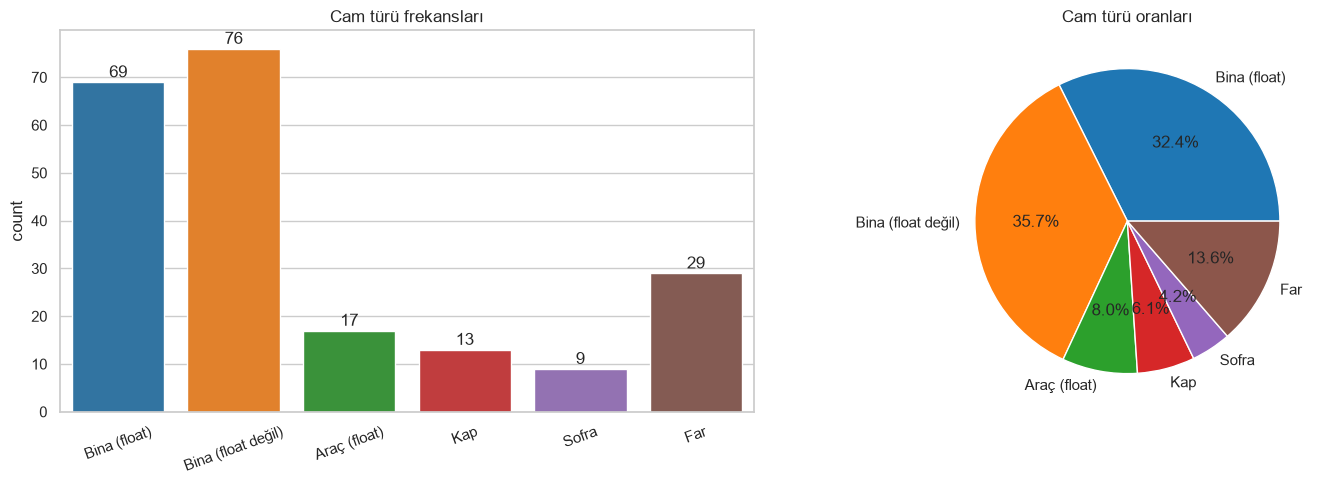

En büyük / en küçük sınıf oranı: 8.4


In [7]:
df["tur_adi"] = df["tur"].map(TUR_ADI)
SIRA = [TUR_ADI[k] for k in sorted(TUR_ADI)]
RENKLER = dict(zip(SIRA, sns.color_palette("tab10", len(SIRA))))

dagilim = pd.DataFrame({"Frekans": df["tur_adi"].value_counts().reindex(SIRA),
                        "Oran (%)": df["tur_adi"].value_counts(normalize=True).reindex(SIRA) * 100})
display(dagilim)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.countplot(data=df, x="tur_adi", order=SIRA, hue="tur_adi", palette=RENKLER, ax=axes[0], legend=False)
for i, v in enumerate(dagilim["Frekans"]):
    axes[0].text(i, v + 1, str(v), ha="center")
axes[0].set_title("Cam türü frekansları")
axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=20)
axes[1].pie(dagilim["Frekans"], labels=SIRA, autopct="%1.1f%%", colors=[RENKLER[s] for s in SIRA])
axes[1].set_title("Cam türü oranları")
plt.tight_layout()
plt.show()
print(f"En büyük / en küçük sınıf oranı: {dagilim['Frekans'].max() / dagilim['Frekans'].min():.1f}")

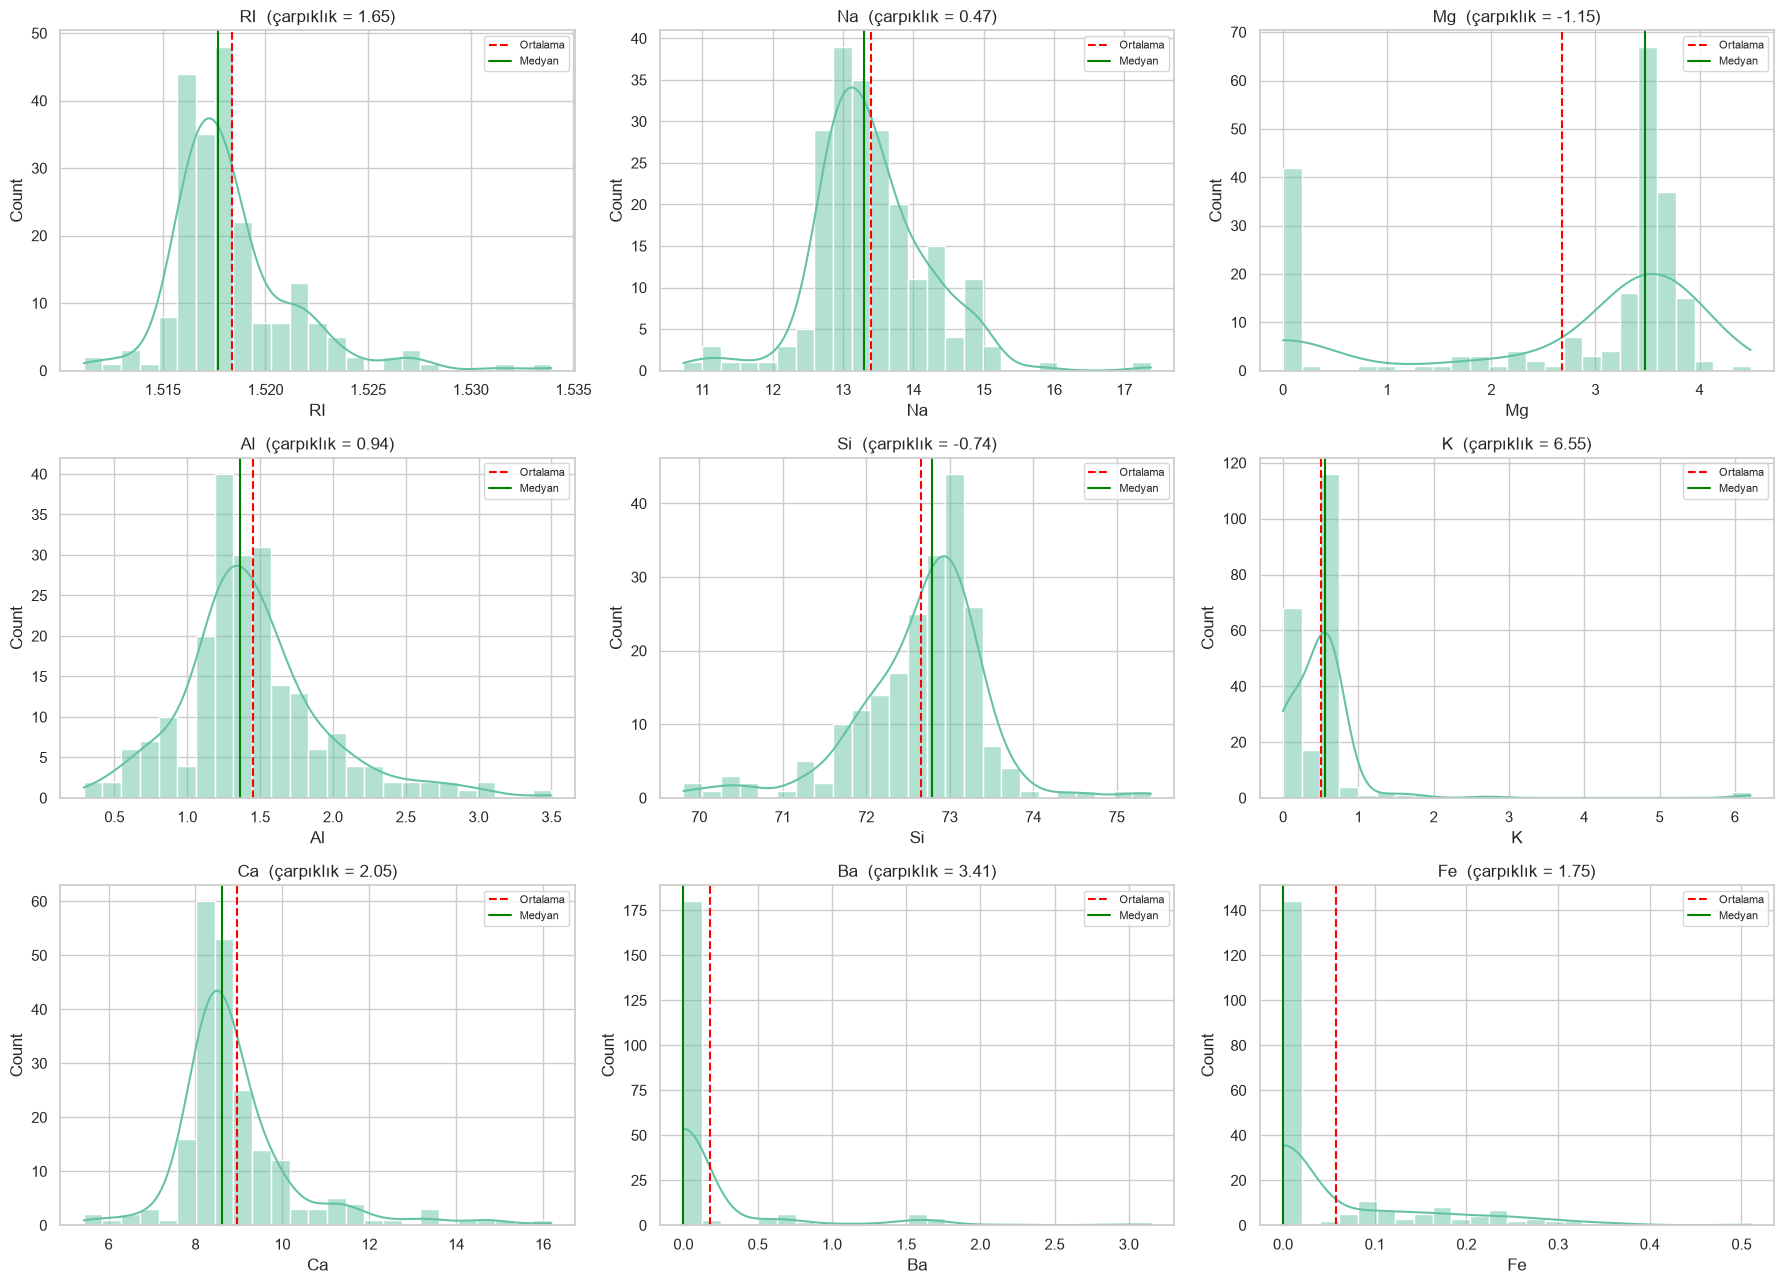

In [8]:
fig, axes = plt.subplots(3, 3, figsize=(18, 13))
for ax, kol in zip(axes.flat, OZELLIKLER):
    sns.histplot(df[kol], kde=True, bins=25, ax=ax)
    ax.axvline(df[kol].mean(), color="red", linestyle="--", label="Ortalama")
    ax.axvline(df[kol].median(), color="green", label="Medyan")
    ax.set_title(f"{kol}  (çarpıklık = {df[kol].skew():.2f})")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

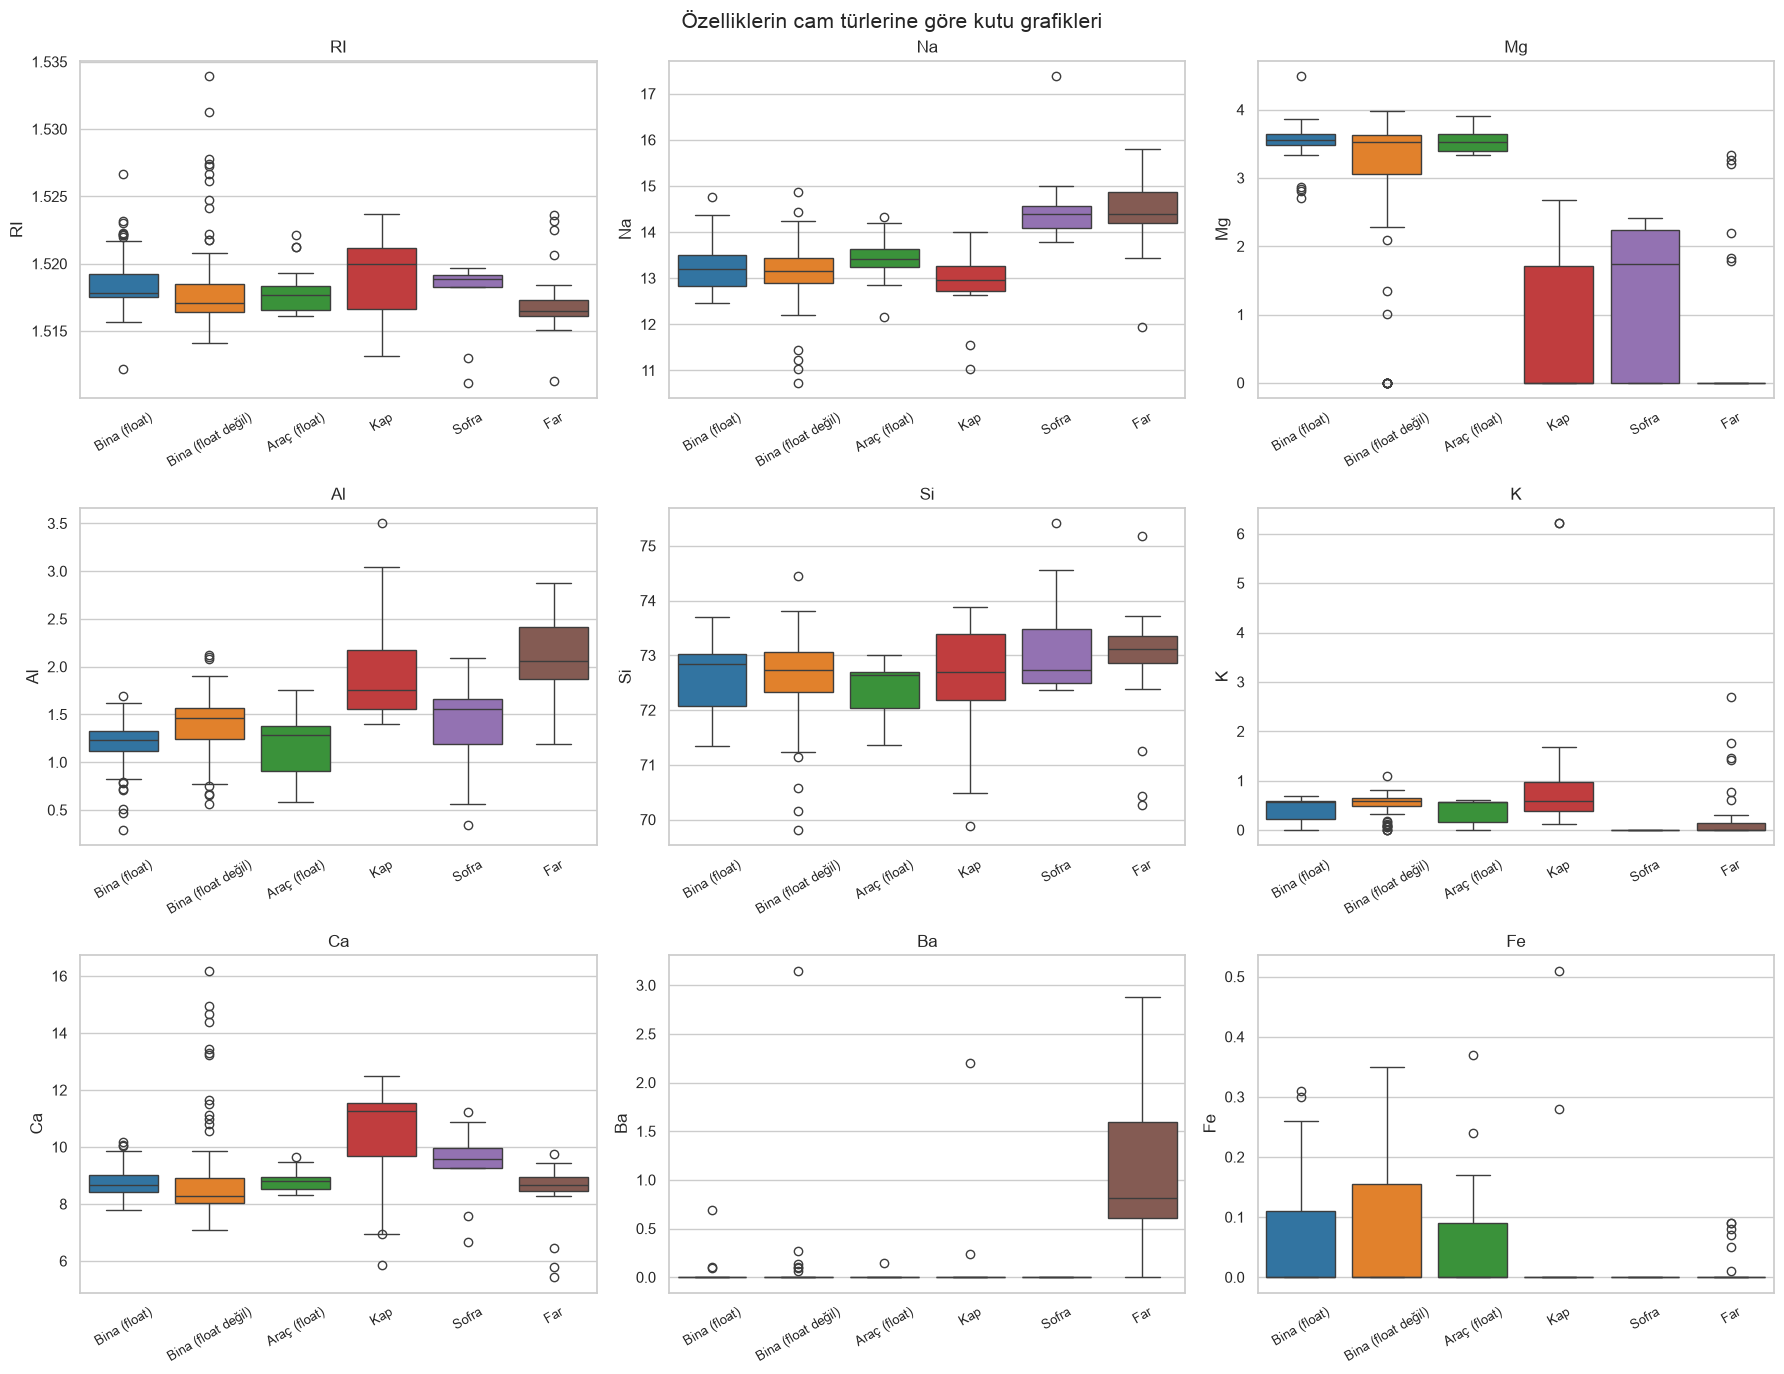

In [9]:
fig, axes = plt.subplots(3, 3, figsize=(18, 14))
for ax, kol in zip(axes.flat, OZELLIKLER):
    sns.boxplot(data=df, x="tur_adi", y=kol, order=SIRA, hue="tur_adi", palette=RENKLER, ax=ax, legend=False)
    ax.set_title(kol)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=30, labelsize=9)
fig.suptitle("Özelliklerin cam türlerine göre kutu grafikleri", fontsize=15)
plt.tight_layout()
plt.show()

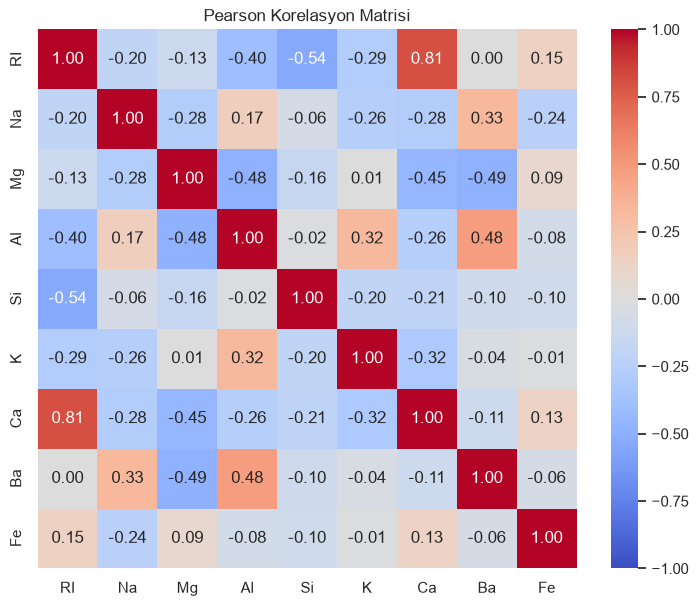

In [10]:
plt.figure(figsize=(9, 7))
sns.heatmap(df[OZELLIKLER].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Pearson Korelasyon Matrisi")
plt.show()

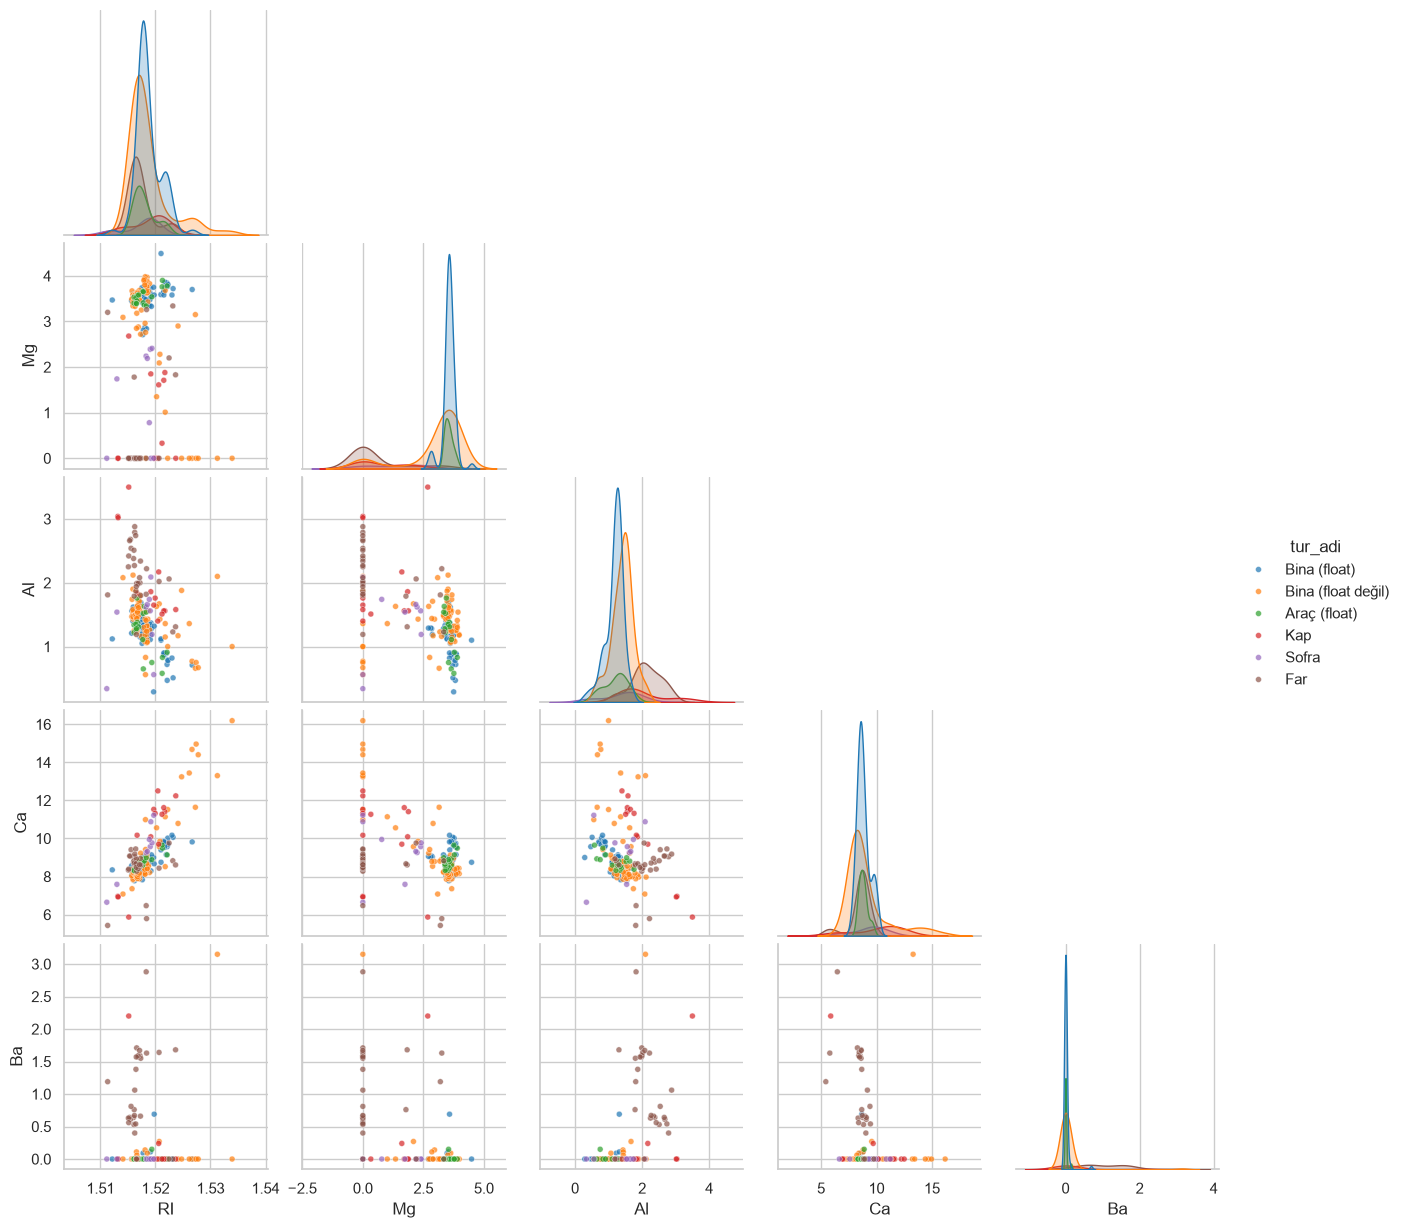

In [11]:
sns.pairplot(df, vars=["RI", "Mg", "Al", "Ca", "Ba"], hue="tur_adi", hue_order=SIRA, palette=RENKLER,
             corner=True, plot_kws={"s": 18, "alpha": 0.7})
plt.show()

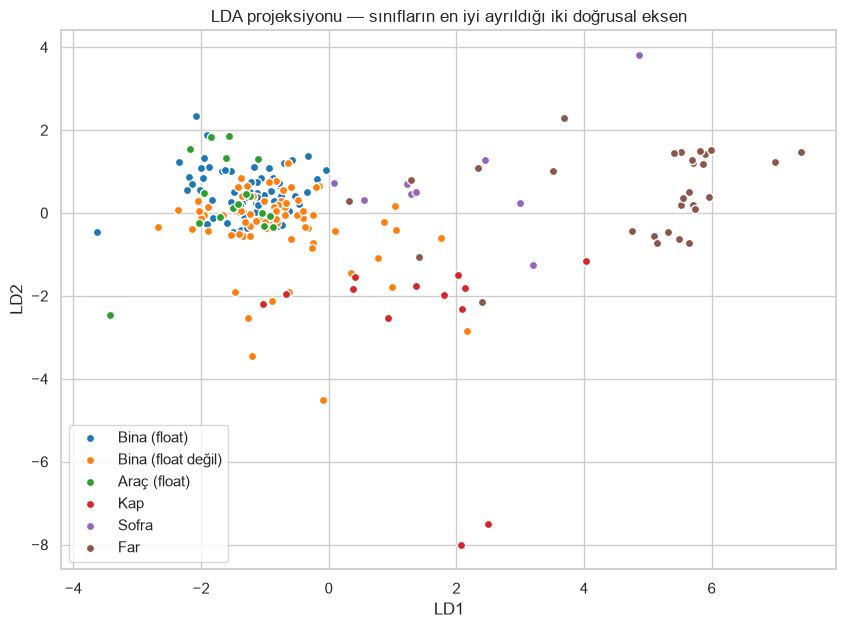

In [12]:
lda = make_pipeline(StandardScaler(), LinearDiscriminantAnalysis(n_components=2)).fit(df[OZELLIKLER], df["tur"])
L = lda.transform(df[OZELLIKLER])
fig, ax = plt.subplots(figsize=(10, 7))
for s in SIRA:
    m = df["tur_adi"] == s
    ax.scatter(L[m, 0], L[m, 1], s=35, color=RENKLER[s], label=s, edgecolor="white")
ax.set_xlabel("LD1")
ax.set_ylabel("LD2")
ax.set_title("LDA projeksiyonu — sınıfların en iyi ayrıldığı iki doğrusal eksen")
ax.legend()
plt.show()

In [13]:
df[OZELLIKLER].describe().T

,count,mean,std,min,25%,50%,75%,max
RI,213.0000,1.5183,0.0030,1.5111,1.5165,1.5177,1.5192,1.5339
Na,213.0000,13.4041,0.8167,10.7300,12.9000,13.3000,13.8100,17.3800
Mg,213.0000,2.6792,1.4437,0.0000,2.0900,3.4800,3.6000,4.4900
Al,213.0000,1.4495,0.4959,0.2900,1.1900,1.3600,1.6300,3.5000
Si,213.0000,72.6551,0.7740,69.8100,72.2800,72.7900,73.0900,75.4100
K,213.0000,0.4989,0.6532,0.0000,0.1300,0.5600,0.6100,6.2100
Ca,213.0000,8.9541,1.4259,5.4300,8.2400,8.6000,9.1500,16.1900
Ba,213.0000,0.1759,0.4982,0.0000,0.0000,0.0000,0.0000,3.1500
Fe,213.0000,0.0573,0.0976,0.0000,0.0000,0.0000,0.1000,0.5100


In [14]:
def aciklayici_tablo(d):
    satirlar = {}
    for kol in d.columns:
        s = d[kol]
        q1, q3 = s.quantile([0.25, 0.75])
        iqr = q3 - q1
        satirlar[kol] = {
            "n": s.count(),
            "Ortalama": s.mean(),
            "Medyan": s.median(),
            "Mod": s.mode().iloc[0],
            "Std. Sapma": s.std(),
            "Varyans": s.var(),
            "Değişim Kats. (%)": s.std() / s.mean() * 100 if s.mean() != 0 else np.nan,
            "Minimum": s.min(),
            "Q1": q1,
            "Q3": q3,
            "Maksimum": s.max(),
            "IQR": iqr,
            "Çarpıklık": s.skew(),
            "Basıklık": s.kurt(),
            "Aykırı (1.5·IQR)": int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()),
            "Shapiro-Wilk p": stats.shapiro(s).pvalue,
        }
    return pd.DataFrame(satirlar).T

aciklayici_tablo(df[OZELLIKLER])

,n,Ortalama,Medyan,Mod,Std. Sapma,Varyans,Değişim Kats. (%),Minimum,Q1,Q3,Maksimum,IQR,Çarpıklık,Basıklık,Aykırı (1.5·IQR),Shapiro-Wilk p
RI,213.0000,1.5183,1.5177,1.5159,0.0030,0.0000,0.1998,1.5111,1.5165,1.5192,1.5339,0.0026,1.6480,5.0389,17.0000,0.0000
Na,213.0000,13.4041,13.3000,13.0000,0.8167,0.6669,6.0926,10.7300,12.9000,13.8100,17.3800,0.9100,0.4657,3.0839,7.0000,0.0000
Mg,213.0000,2.6792,3.4800,0.0000,1.4437,2.0842,53.8851,0.0000,2.0900,3.6000,4.4900,1.5100,-1.1461,-0.4263,0.0000,0.0000
Al,213.0000,1.4495,1.3600,1.5400,0.4959,0.2459,34.2139,0.2900,1.1900,1.6300,3.5000,0.4400,0.9384,2.1166,17.0000,0.0000
Si,213.0000,72.6551,72.7900,72.8600,0.7740,0.5991,1.0653,69.8100,72.2800,73.0900,75.4100,0.8100,-0.7446,3.0219,12.0000,0.0000
K,213.0000,0.4989,0.5600,0.0000,0.6532,0.4267,130.9321,0.0000,0.1300,0.6100,6.2100,0.4800,6.5454,54.5426,7.0000,0.0000
Ca,213.0000,8.9541,8.6000,8.0300,1.4259,2.0331,15.9244,5.4300,8.2400,9.1500,16.1900,0.9100,2.0508,6.6711,27.0000,0.0000
Ba,213.0000,0.1759,0.0000,0.0000,0.4982,0.2482,283.3053,0.0000,0.0000,0.0000,3.1500,0.0000,3.4067,12.4649,38.0000,0.0000
Fe,213.0000,0.0573,0.0000,0.0000,0.0976,0.0095,170.3814,0.0000,0.0000,0.1000,0.5100,0.1000,1.7472,2.6340,12.0000,0.0000


In [15]:
print("Cam türlerine göre ortalamalar")
df.groupby("tur_adi")[OZELLIKLER].mean().reindex(SIRA)

Cam türlerine göre ortalamalar


,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe
tur_adi,,,,,,,,,
Bina (float),1.5187,13.2283,3.5486,1.1739,72.6314,0.4523,8.7861,0.0129,0.0578
Bina (float değil),1.5186,13.1117,3.0021,1.4082,72.5980,0.5211,9.0737,0.0503,0.0797
Araç (float),1.5180,13.4371,3.5435,1.2012,72.4047,0.4065,8.7829,0.0088,0.0571
Kap,1.5189,12.8277,0.7738,2.0338,72.3662,1.4700,10.1238,0.1877,0.0608
Sofra,1.5175,14.6467,1.3056,1.3667,73.2067,0.0000,9.3567,0.0000,0.0000
Far,1.5171,14.4421,0.5383,2.1228,72.9659,0.3252,8.4914,1.0400,0.0134


In [16]:
print("Cam türlerine göre standart sapmalar")
df.groupby("tur_adi")[OZELLIKLER].std().reindex(SIRA)

Cam türlerine göre standart sapmalar


,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe
tur_adi,,,,,,,,,
Bina (float),0.0022,0.4889,0.2467,0.2618,0.5642,0.2125,0.5713,0.0844,0.0895
Bina (float değil),0.0038,0.6642,1.2157,0.3183,0.7246,0.2137,1.9216,0.3623,0.1064
Araç (float),0.0019,0.5069,0.1628,0.3475,0.5123,0.2299,0.3801,0.0364,0.1079
Kap,0.0033,0.7770,0.9991,0.6939,1.2823,2.1387,2.1838,0.6083,0.1556
Sofra,0.0031,1.0840,1.0971,0.5719,1.0795,0.0000,1.4499,0.0000,0.0000
Far,0.0025,0.6864,1.1177,0.4427,0.9402,0.6685,0.9735,0.6653,0.0298


In [17]:
ayrim = []
for kol in OZELLIKLER:
    gruplar = [g[kol].values for _, g in df.groupby("tur")]
    h, p = stats.kruskal(*gruplar)
    ss_b = sum(len(g) * (g.mean() - df[kol].mean()) ** 2 for g in gruplar)
    ss_t = ((df[kol] - df[kol].mean()) ** 2).sum()
    ayrim.append({"Özellik": kol, "Kruskal-Wallis H": h, "p-değeri": p, "η²": ss_b / ss_t,
                  "Anlamlı mı? (α=0.05)": "Evet" if p < 0.05 else "Hayır"})
pd.DataFrame(ayrim).set_index("Özellik").sort_values("η²", ascending=False)

,Kruskal-Wallis H,p-değeri,η²,Anlamlı mı? (α=0.05)
Özellik,,,,
Mg,99.7096,0.0000,0.6108,Evet
Ba,127.5509,0.0000,0.4834,Evet
Al,88.5706,0.0000,0.4615,Evet
Na,77.8942,0.0000,0.4110,Evet
K,50.8116,0.0000,0.1737,Evet
Ca,18.7475,0.0021,0.0673,Evet
Si,19.5980,0.0015,0.0628,Evet
Fe,13.2702,0.0210,0.0613,Evet
RI,18.4053,0.0025,0.0363,Evet


In [18]:
X = df[OZELLIKLER]
y = df["tur"]
ETIKETLER = sorted(y.unique())
ETIKET_ADLARI = [TUR_ADI[k] for k in ETIKETLER]

X_egitim, X_test, y_egitim, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)

pd.DataFrame({"Eğitim": y_egitim.value_counts(), "Test": y_test.value_counts()}).reindex(ETIKETLER) \
  .rename(index=TUR_ADI).assign(Toplam=lambda d: d.sum(axis=1))

,Eğitim,Test,Toplam
tur,,,
Bina (float),51,18,69
Bina (float değil),57,19,76
Araç (float),13,4,17
Kap,10,3,13
Sofra,7,2,9
Far,21,8,29


In [19]:
modeller = {
    "Lojistik Regresyon (softmax)": make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)),
    "SVM (RBF)": make_pipeline(StandardScaler(), SVC(C=10)),
    "k-NN (k=1)": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=1)),
    "Karar Ağacı": DecisionTreeClassifier(random_state=42),
    "Rastgele Orman": RandomForestClassifier(n_estimators=500, random_state=42),
    "Ekstra Ağaçlar": ExtraTreesClassifier(n_estimators=500, random_state=42),
    "Gradyan Artırma": GradientBoostingClassifier(random_state=42),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
karsilastirma = []
for ad, model in modeller.items():
    s = cross_validate(model, X_egitim, y_egitim, cv=cv,
                       scoring=["accuracy", "balanced_accuracy", "f1_macro", "f1_weighted"])
    karsilastirma.append({"Model": ad, "Doğruluk": s["test_accuracy"].mean(),
                          "Dengeli doğruluk": s["test_balanced_accuracy"].mean(),
                          "Makro F1": s["test_f1_macro"].mean(), "Makro F1 std": s["test_f1_macro"].std(),
                          "Ağırlıklı F1": s["test_f1_weighted"].mean()})
karsilastirma = pd.DataFrame(karsilastirma).set_index("Model").sort_values("Makro F1", ascending=False)
karsilastirma.style.highlight_max(color="lightgreen", subset=["Doğruluk", "Dengeli doğruluk", "Makro F1", "Ağırlıklı F1"]) \
                   .format("{:.4f}")

,Doğruluk,Dengeli doğruluk,Makro F1,Makro F1 std,Ağırlıklı F1
Model,,,,,
Rastgele Orman,0.7605,0.7105,0.7171,0.0472,0.7494
Ekstra Ağaçlar,0.7419,0.6621,0.6655,0.0806,0.7289
Gradyan Artırma,0.7353,0.6349,0.6451,0.1190,0.7239
k-NN (k=1),0.6599,0.6092,0.6081,0.1097,0.6563
Karar Ağacı,0.6603,0.6120,0.6023,0.0699,0.6505
SVM (RBF),0.6790,0.6022,0.5772,0.1181,0.6509
Lojistik Regresyon (softmax),0.5913,0.5049,0.4717,0.0377,0.5542


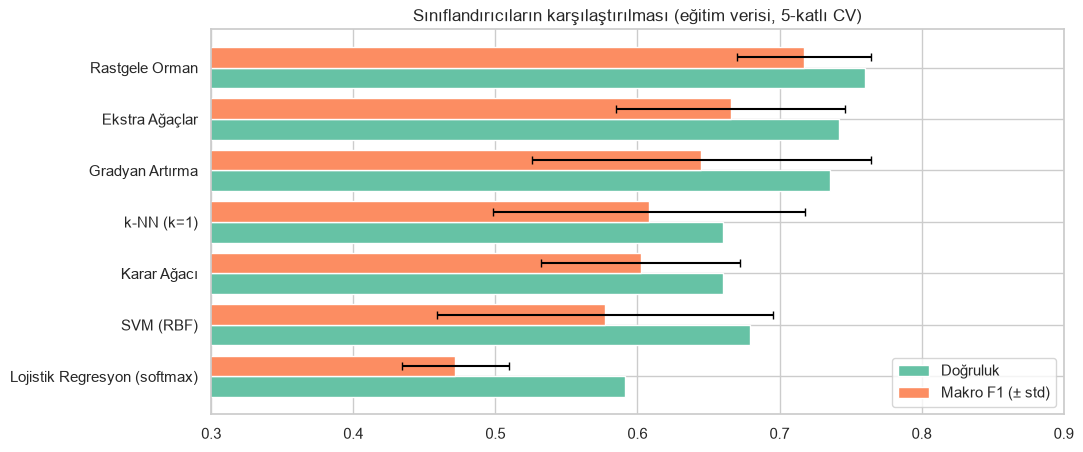

Çapraz doğrulamada makro F1'i en yüksek model: Rastgele Orman


In [20]:
fig, ax = plt.subplots(figsize=(11, 5))
k = karsilastirma.sort_values("Makro F1")
y_poz = np.arange(len(k))
ax.barh(y_poz - 0.2, k["Doğruluk"], height=0.4, label="Doğruluk")
ax.barh(y_poz + 0.2, k["Makro F1"], height=0.4, xerr=k["Makro F1 std"], capsize=3, label="Makro F1 (± std)")
ax.set_yticks(y_poz, k.index)
ax.set_xlim(0.3, 0.9)
ax.set_title("Sınıflandırıcıların karşılaştırılması (eğitim verisi, 5-katlı CV)")
ax.legend(loc="lower right")
plt.show()

EN_IYI = karsilastirma.index[0]
print(f"Çapraz doğrulamada makro F1'i en yüksek model: {EN_IYI}")

In [21]:
model = modeller[EN_IYI]
model.fit(X_egitim, y_egitim)
y_tahmin = model.predict(X_test)
y_olasilik = model.predict_proba(X_test)
SINIF_SIRASI = list(model.classes_)

sonuc = X_test[["RI", "Mg", "Al", "Ba"]].copy()
sonuc["Gerçek"] = y_test.map(TUR_ADI)
sonuc["Tahmin"] = pd.Series(y_tahmin, index=X_test.index).map(TUR_ADI)
sonuc["Güven (maks. olasılık)"] = y_olasilik.max(axis=1)
sonuc["Doğru mu?"] = np.where(sonuc["Gerçek"] == sonuc["Tahmin"], "✓", "✗")
print("Test verisi tahminlerinden örnekler:")
sonuc.head(12)

Test verisi tahminlerinden örnekler:


,RI,Mg,Al,Ba,Gerçek,Tahmin,Güven (maks. olasılık),Doğru mu?
64,1.5210,3.5900,1.1200,0.0000,Bina (float),Bina (float),0.8380,✓
92,1.5159,3.3400,1.4700,0.0000,Bina (float değil),Bina (float değil),0.7520,✓
131,1.5181,3.9800,1.1800,0.0000,Bina (float değil),Bina (float değil),0.7100,✓
150,1.5213,3.9000,0.8300,0.0000,Araç (float),Bina (float),0.5780,✗
51,1.5181,2.8700,1.1900,0.0000,Bina (float),Bina (float),0.5220,✓
94,1.5186,3.4300,1.4300,0.0000,Bina (float değil),Bina (float),0.4000,✗
14,1.5176,3.5900,1.3100,0.0000,Bina (float),Bina (float),0.9640,✓
205,1.5165,0.0000,1.8700,1.3800,Far,Far,0.9780,✓
97,1.5169,2.8800,1.7100,0.0000,Bina (float değil),Bina (float değil),0.6020,✓
192,1.5172,0.0000,2.0000,1.5900,Far,Far,0.9880,✓


In [22]:
print(f"Eğitim doğruluğu : {accuracy_score(y_egitim, model.predict(X_egitim)):.4f}")
print(f"Test doğruluğu   : {accuracy_score(y_test, y_tahmin):.4f}")
print(f"CV doğruluğu     : {karsilastirma.loc[EN_IYI, 'Doğruluk']:.4f}")
print(f"Test makro F1    : {f1_score(y_test, y_tahmin, average='macro'):.4f}")
print(f"CV makro F1      : {karsilastirma.loc[EN_IYI, 'Makro F1']:.4f} ± {karsilastirma.loc[EN_IYI, 'Makro F1 std']:.4f}")

Eğitim doğruluğu : 1.0000
Test doğruluğu   : 0.7963
CV doğruluğu     : 0.7605
Test makro F1    : 0.7730
CV makro F1      : 0.7171 ± 0.0472


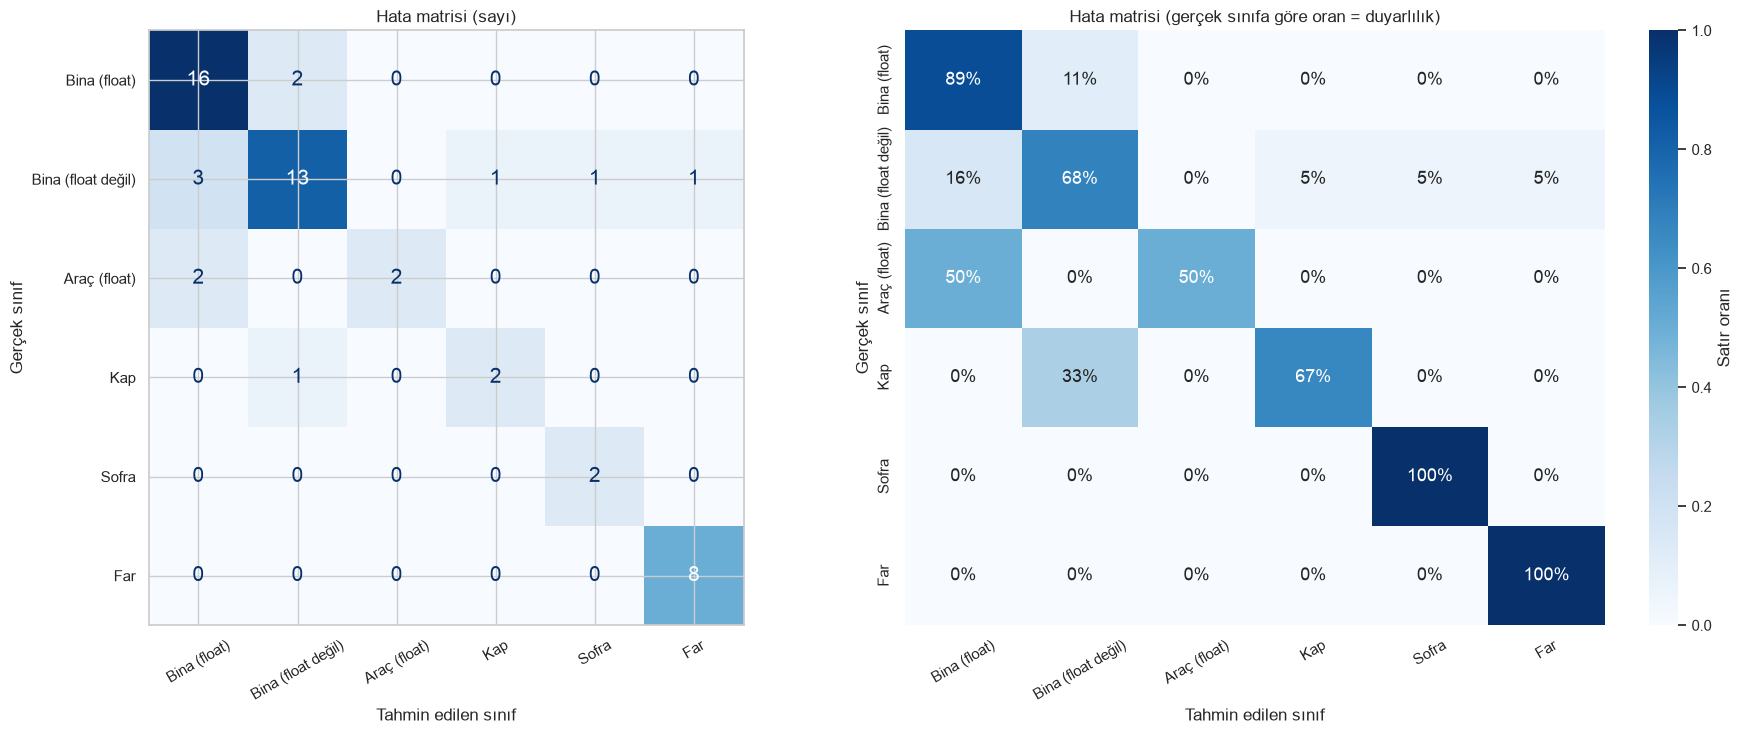

In [23]:
cm = confusion_matrix(y_test, y_tahmin, labels=ETIKETLER)
cm_satir = confusion_matrix(y_test, y_tahmin, labels=ETIKETLER, normalize="true")

fig, axes = plt.subplots(1, 2, figsize=(19, 7.5))
ConfusionMatrixDisplay(cm, display_labels=ETIKET_ADLARI).plot(cmap="Blues", ax=axes[0], colorbar=False,
                                                               text_kw={"fontsize": 15}, xticks_rotation=30)
axes[0].set_title("Hata matrisi (sayı)")
axes[0].set_xlabel("Tahmin edilen sınıf")
axes[0].set_ylabel("Gerçek sınıf")

sns.heatmap(cm_satir, annot=True, fmt=".0%", cmap="Blues", vmin=0, vmax=1, ax=axes[1], annot_kws={"fontsize": 13},
            xticklabels=ETIKET_ADLARI, yticklabels=ETIKET_ADLARI, cbar_kws={"label": "Satır oranı"})
axes[1].set_title("Hata matrisi (gerçek sınıfa göre oran = duyarlılık)")
axes[1].set_xlabel("Tahmin edilen sınıf")
axes[1].set_ylabel("Gerçek sınıf")
axes[1].tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

In [24]:
n = cm.sum()
sinif_tablo = []
for i, ad in enumerate(ETIKET_ADLARI):
    tp = cm[i, i]
    fn = cm[i, :].sum() - tp
    fp = cm[:, i].sum() - tp
    tn = n - tp - fn - fp
    sinif_tablo.append({"Sınıf": ad, "Destek": cm[i, :].sum(), "TP": tp, "FN": fn, "FP": fp, "TN": tn,
                        "Duyarlılık": tp / (tp + fn), "Özgüllük": tn / (tn + fp),
                        "Kesinlik": tp / (tp + fp) if tp + fp else np.nan})
sinif_tablo = pd.DataFrame(sinif_tablo).set_index("Sınıf")
sinif_tablo

,Destek,TP,FN,FP,TN,Duyarlılık,Özgüllük,Kesinlik
Sınıf,,,,,,,,
Bina (float),18,16,2,5,31,0.8889,0.8611,0.7619
Bina (float değil),19,13,6,3,32,0.6842,0.9143,0.8125
Araç (float),4,2,2,0,50,0.5000,1.0000,1.0000
Kap,3,2,1,1,50,0.6667,0.9804,0.6667
Sofra,2,2,0,1,51,1.0000,0.9808,0.6667
Far,8,8,0,1,45,1.0000,0.9783,0.8889


In [25]:
karisan = []
for i, g in enumerate(ETIKET_ADLARI):
    for j, t in enumerate(ETIKET_ADLARI):
        if i != j and cm[i, j] > 0:
            karisan.append({"Gerçek sınıf": g, "Tahmin edilen": t, "Sayı": cm[i, j],
                            "Gerçek sınıfın %'si": cm[i, j] / cm[i, :].sum() * 100})
pd.DataFrame(karisan).sort_values("Sayı", ascending=False).reset_index(drop=True)

,Gerçek sınıf,Tahmin edilen,Sayı,Gerçek sınıfın %'si
0,Bina (float değil),Bina (float),3,15.7895
1,Bina (float),Bina (float değil),2,11.1111
2,Araç (float),Bina (float),2,50.0000
3,Bina (float değil),Kap,1,5.2632
4,Bina (float değil),Sofra,1,5.2632
5,Bina (float değil),Far,1,5.2632
6,Kap,Bina (float değil),1,33.3333


In [26]:
olasilik_df = pd.DataFrame(y_olasilik, columns=[TUR_ADI[c] for c in SINIF_SIRASI], index=X_test.index)
hatali = pd.concat([sonuc[["Gerçek", "Tahmin", "Güven (maks. olasılık)"]], olasilik_df], axis=1)
hatali = hatali[sonuc["Doğru mu?"] == "✗"]
hatali.style.background_gradient(cmap="Oranges", subset=list(olasilik_df.columns), axis=1).format(precision=2)

,Gerçek,Tahmin,Güven (maks. olasılık),Bina (float),Bina (float değil),Araç (float),Kap,Sofra,Far
150,Araç (float),Bina (float),0.58,0.58,0.06,0.12,0.00,0.23,0.02
94,Bina (float değil),Bina (float),0.40,0.40,0.32,0.25,0.00,0.01,0.02
143,Bina (float değil),Bina (float),0.36,0.36,0.34,0.26,0.00,0.01,0.03
2,Bina (float),Bina (float değil),0.91,0.05,0.91,0.04,0.00,0.00,0.00
108,Bina (float değil),Sofra,0.52,0.02,0.32,0.02,0.07,0.52,0.05
128,Bina (float değil),Kap,0.37,0.01,0.33,0.04,0.37,0.20,0.05
151,Araç (float),Bina (float),0.59,0.59,0.05,0.34,0.00,0.02,0.00
140,Bina (float değil),Bina (float),0.49,0.49,0.45,0.06,0.00,0.00,0.00
172,Kap,Bina (float değil),0.51,0.06,0.51,0.00,0.34,0.06,0.02
20,Bina (float),Bina (float değil),0.52,0.40,0.52,0.07,0.01,0.00,0.00


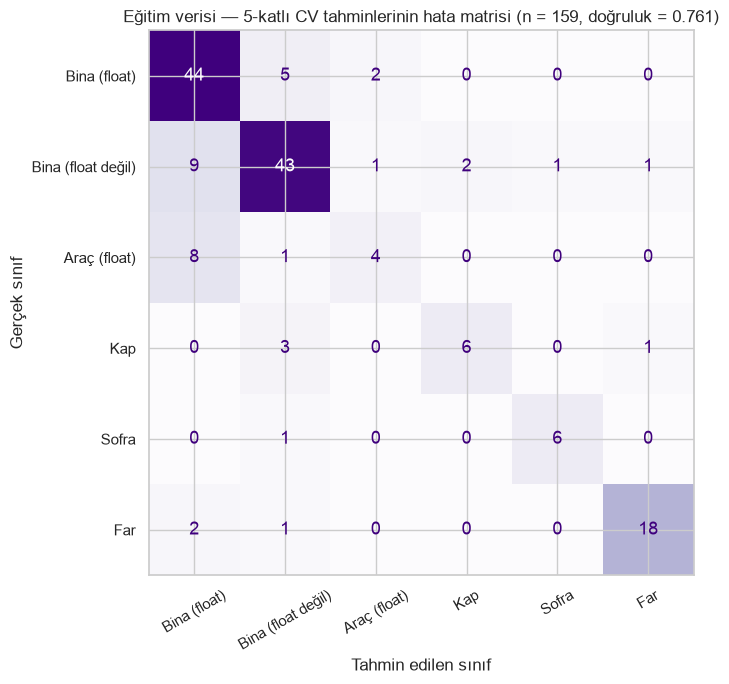

In [27]:
y_cv = cross_val_predict(modeller[EN_IYI], X_egitim, y_egitim, cv=cv)
fig, ax = plt.subplots(figsize=(9, 7))
ConfusionMatrixDisplay(confusion_matrix(y_egitim, y_cv, labels=ETIKETLER), display_labels=ETIKET_ADLARI) \
    .plot(cmap="Purples", ax=ax, colorbar=False, text_kw={"fontsize": 13}, xticks_rotation=30)
ax.set_title(f"Eğitim verisi — 5-katlı CV tahminlerinin hata matrisi (n = {len(y_egitim)}, doğruluk = {accuracy_score(y_egitim, y_cv):.3f})")
ax.set_xlabel("Tahmin edilen sınıf")
ax.set_ylabel("Gerçek sınıf")
plt.tight_layout()
plt.show()

In [28]:
print(f"SINIFLANDIRMA RAPORU — {EN_IYI} (test verisi)")
print("=" * 70)
print(classification_report(y_test, y_tahmin, labels=ETIKETLER, target_names=ETIKET_ADLARI, digits=4, zero_division=0))

SINIFLANDIRMA RAPORU — Rastgele Orman (test verisi)
                    precision    recall  f1-score   support

      Bina (float)     0.7619    0.8889    0.8205        18
Bina (float değil)     0.8125    0.6842    0.7429        19
      Araç (float)     1.0000    0.5000    0.6667         4
               Kap     0.6667    0.6667    0.6667         3
             Sofra     0.6667    1.0000    0.8000         2
               Far     0.8889    1.0000    0.9412         8

          accuracy                         0.7963        54
         macro avg     0.7994    0.7900    0.7730        54
      weighted avg     0.8073    0.7963    0.7904        54



In [29]:
rapor_df = pd.DataFrame(classification_report(y_test, y_tahmin, labels=ETIKETLER, target_names=ETIKET_ADLARI,
                                              output_dict=True, zero_division=0)).T
rapor_df.loc["accuracy", ["precision", "recall", "support"]] = [np.nan, np.nan, len(y_test)]
rapor_df.columns = ["Kesinlik", "Duyarlılık", "F1-Skoru", "Destek"]
rapor_df = rapor_df.rename(index={"accuracy": "Doğruluk", "macro avg": "Makro ortalama", "weighted avg": "Ağırlıklı ortalama"})
rapor_df.style.background_gradient(cmap="RdYlGn", subset=["Kesinlik", "Duyarlılık", "F1-Skoru"], vmin=0.4, vmax=1) \
              .format({"Kesinlik": "{:.4f}", "Duyarlılık": "{:.4f}", "F1-Skoru": "{:.4f}", "Destek": "{:.0f}"})

,Kesinlik,Duyarlılık,F1-Skoru,Destek
Bina (float),0.7619,0.8889,0.8205,18
Bina (float değil),0.8125,0.6842,0.7429,19
Araç (float),1.0000,0.5000,0.6667,4
Kap,0.6667,0.6667,0.6667,3
Sofra,0.6667,1.0000,0.8000,2
Far,0.8889,1.0000,0.9412,8
Doğruluk,nan,nan,0.7963,54
Makro ortalama,0.7994,0.7900,0.7730,54
Ağırlıklı ortalama,0.8073,0.7963,0.7904,54


In [30]:
y_test_bin = label_binarize(y_test, classes=SINIF_SIRASI)
ek = pd.Series({
    "Doğruluk (Accuracy)": accuracy_score(y_test, y_tahmin),
    "Dengeli doğruluk": balanced_accuracy_score(y_test, y_tahmin),
    "Makro kesinlik": precision_score(y_test, y_tahmin, average="macro", zero_division=0),
    "Makro duyarlılık": recall_score(y_test, y_tahmin, average="macro"),
    "Makro F1": f1_score(y_test, y_tahmin, average="macro"),
    "Mikro F1 (= doğruluk)": f1_score(y_test, y_tahmin, average="micro"),
    "Ağırlıklı F1": f1_score(y_test, y_tahmin, average="weighted"),
    "ROC-AUC (OvR, makro)": roc_auc_score(y_test, y_olasilik, multi_class="ovr", average="macro"),
    "ROC-AUC (OvR, ağırlıklı)": roc_auc_score(y_test, y_olasilik, multi_class="ovr", average="weighted"),
    "Top-2 doğruluk": top_k_accuracy_score(y_test, y_olasilik, k=2, labels=SINIF_SIRASI),
    "Matthews korelasyon katsayısı (MCC)": matthews_corrcoef(y_test, y_tahmin),
    "Cohen Kappa": cohen_kappa_score(y_test, y_tahmin),
    "Log-loss (↓)": log_loss(y_test, y_olasilik, labels=SINIF_SIRASI),
    "Taban doğruluk (hep en büyük sınıfı tahmin)": y_test.value_counts(normalize=True).max(),
}).to_frame("Değer")
ek

,Değer
Doğruluk (Accuracy),0.7963
Dengeli doğruluk,0.7900
Makro kesinlik,0.7994
Makro duyarlılık,0.7900
Makro F1,0.7730
Mikro F1 (= doğruluk),0.7963
Ağırlıklı F1,0.7904
"ROC-AUC (OvR, makro)",0.9686
"ROC-AUC (OvR, ağırlıklı)",0.9550
Top-2 doğruluk,0.9815


In [31]:
import warnings
warnings.filterwarnings("ignore", message="y_pred contains classes not in y_true")
rng = np.random.default_rng(42)
yt, yp = y_test.values, y_tahmin
bs = {"Doğruluk": [], "Dengeli doğruluk": [], "Makro F1": [], "Ağırlıklı F1": []}
for _ in range(2000):
    i = rng.integers(0, len(yt), len(yt))
    bs["Doğruluk"].append(accuracy_score(yt[i], yp[i]))
    bs["Dengeli doğruluk"].append(balanced_accuracy_score(yt[i], yp[i]))
    bs["Makro F1"].append(f1_score(yt[i], yp[i], average="macro", zero_division=0))
    bs["Ağırlıklı F1"].append(f1_score(yt[i], yp[i], average="weighted", zero_division=0))
pd.DataFrame({k: {"Ortalama": np.mean(v), "%95 GA Alt": np.percentile(v, 2.5), "%95 GA Üst": np.percentile(v, 97.5)}
              for k, v in bs.items()}).T

,Ortalama,%95 GA Alt,%95 GA Üst
Doğruluk,0.7957,0.6852,0.9074
Dengeli doğruluk,0.7881,0.6232,0.9316
Makro F1,0.7449,0.5468,0.8975
Ağırlıklı F1,0.7897,0.6652,0.9038


In [32]:
print("Çapraz doğrulama tahminleriyle (eğitim verisi, n = %d) sınıflandırma raporu" % len(y_egitim))
print(classification_report(y_egitim, y_cv, labels=ETIKETLER, target_names=ETIKET_ADLARI, digits=3, zero_division=0))

Çapraz doğrulama tahminleriyle (eğitim verisi, n = 159) sınıflandırma raporu
                    precision    recall  f1-score   support

      Bina (float)      0.698     0.863     0.772        51
Bina (float değil)      0.796     0.754     0.775        57
      Araç (float)      0.571     0.308     0.400        13
               Kap      0.750     0.600     0.667        10
             Sofra      0.857     0.857     0.857         7
               Far      0.900     0.857     0.878        21

          accuracy                          0.761       159
         macro avg      0.762     0.707     0.725       159
      weighted avg      0.760     0.761     0.754       159



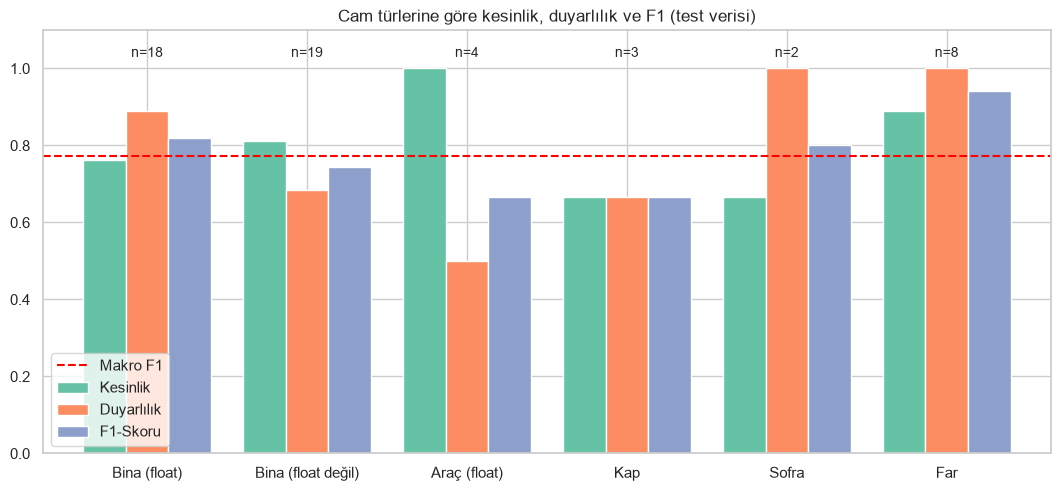

In [33]:
sinif_olcut = rapor_df.loc[ETIKET_ADLARI, ["Kesinlik", "Duyarlılık", "F1-Skoru"]]
ax = sinif_olcut.plot.bar(figsize=(13, 5.5), rot=0, width=0.8)
for i, d in enumerate(rapor_df.loc[ETIKET_ADLARI, "Destek"]):
    ax.text(i, 1.03, f"n={int(d)}", ha="center", fontsize=10)
ax.axhline(rapor_df.loc["Makro ortalama", "F1-Skoru"], color="red", linestyle="--", label="Makro F1")
ax.set_ylim(0, 1.1)
ax.set_title("Cam türlerine göre kesinlik, duyarlılık ve F1 (test verisi)")
ax.legend(loc="lower left")
plt.show()

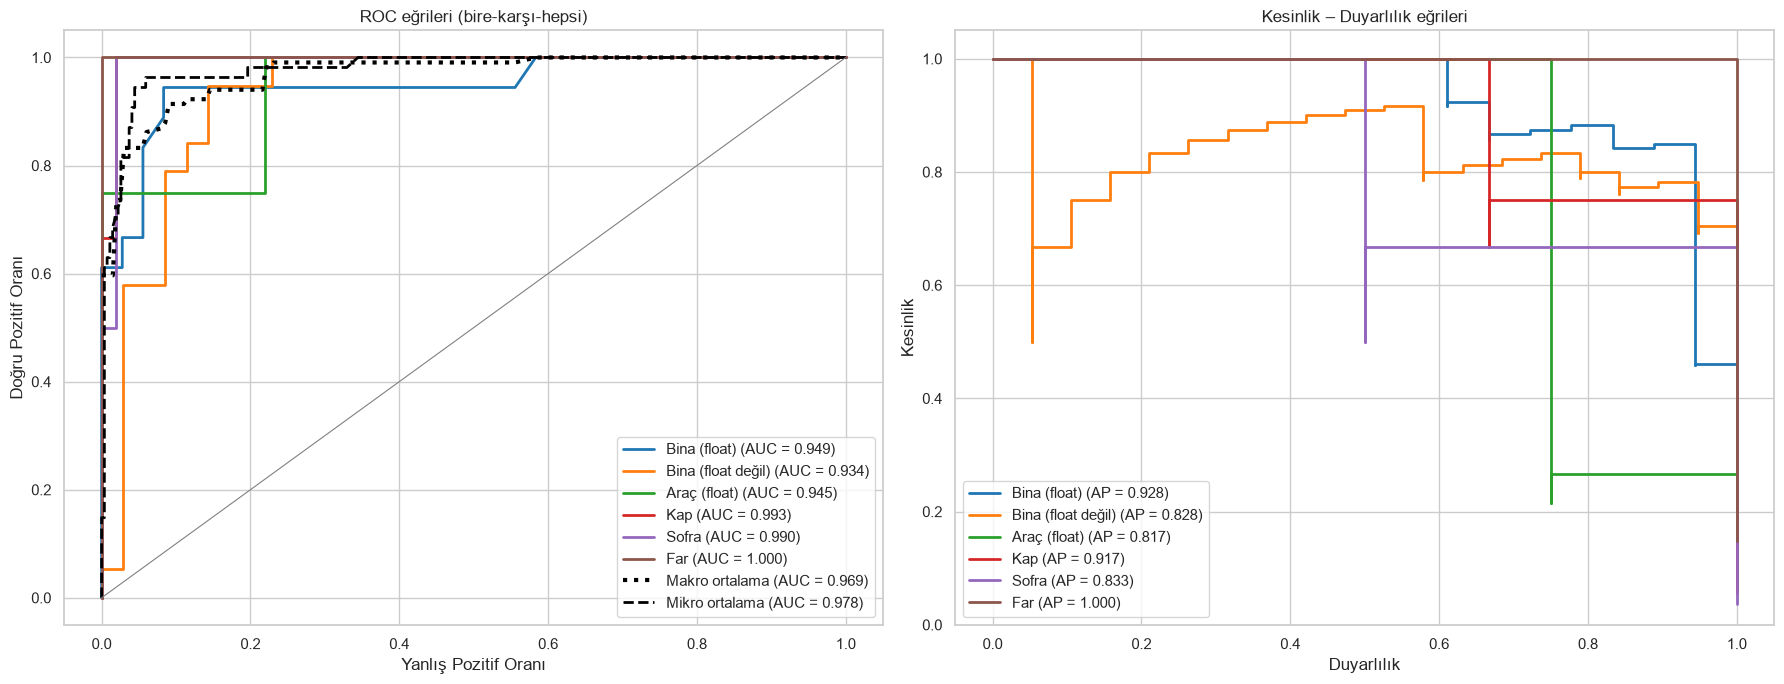

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7))
renk_listesi = [RENKLER[TUR_ADI[c]] for c in SINIF_SIRASI]
tum_fpr = np.linspace(0, 1, 200)
ort_tpr = np.zeros_like(tum_fpr)
for i, c in enumerate(SINIF_SIRASI):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_olasilik[:, i])
    axes[0].plot(fpr, tpr, color=renk_listesi[i], linewidth=2, label=f"{TUR_ADI[c]} (AUC = {auc(fpr, tpr):.3f})")
    ort_tpr += np.interp(tum_fpr, fpr, tpr)
ort_tpr /= len(SINIF_SIRASI)
fpr_mikro, tpr_mikro, _ = roc_curve(y_test_bin.ravel(), y_olasilik.ravel())
axes[0].plot(tum_fpr, ort_tpr, "k:", linewidth=3, label=f"Makro ortalama (AUC = {auc(tum_fpr, ort_tpr):.3f})")
axes[0].plot(fpr_mikro, tpr_mikro, "k--", linewidth=2, label=f"Mikro ortalama (AUC = {auc(fpr_mikro, tpr_mikro):.3f})")
axes[0].plot([0, 1], [0, 1], color="gray", linewidth=0.8)
axes[0].set_xlabel("Yanlış Pozitif Oranı")
axes[0].set_ylabel("Doğru Pozitif Oranı")
axes[0].set_title("ROC eğrileri (bire-karşı-hepsi)")
axes[0].legend(loc="lower right")

for i, c in enumerate(SINIF_SIRASI):
    kes, duy, _ = precision_recall_curve(y_test_bin[:, i], y_olasilik[:, i])
    ap = average_precision_score(y_test_bin[:, i], y_olasilik[:, i])
    axes[1].step(duy, kes, where="post", color=renk_listesi[i], linewidth=2, label=f"{TUR_ADI[c]} (AP = {ap:.3f})")
axes[1].set_xlabel("Duyarlılık")
axes[1].set_ylabel("Kesinlik")
axes[1].set_ylim(0, 1.05)
axes[1].set_title("Kesinlik – Duyarlılık eğrileri")
axes[1].legend(loc="lower left")
plt.tight_layout()
plt.show()

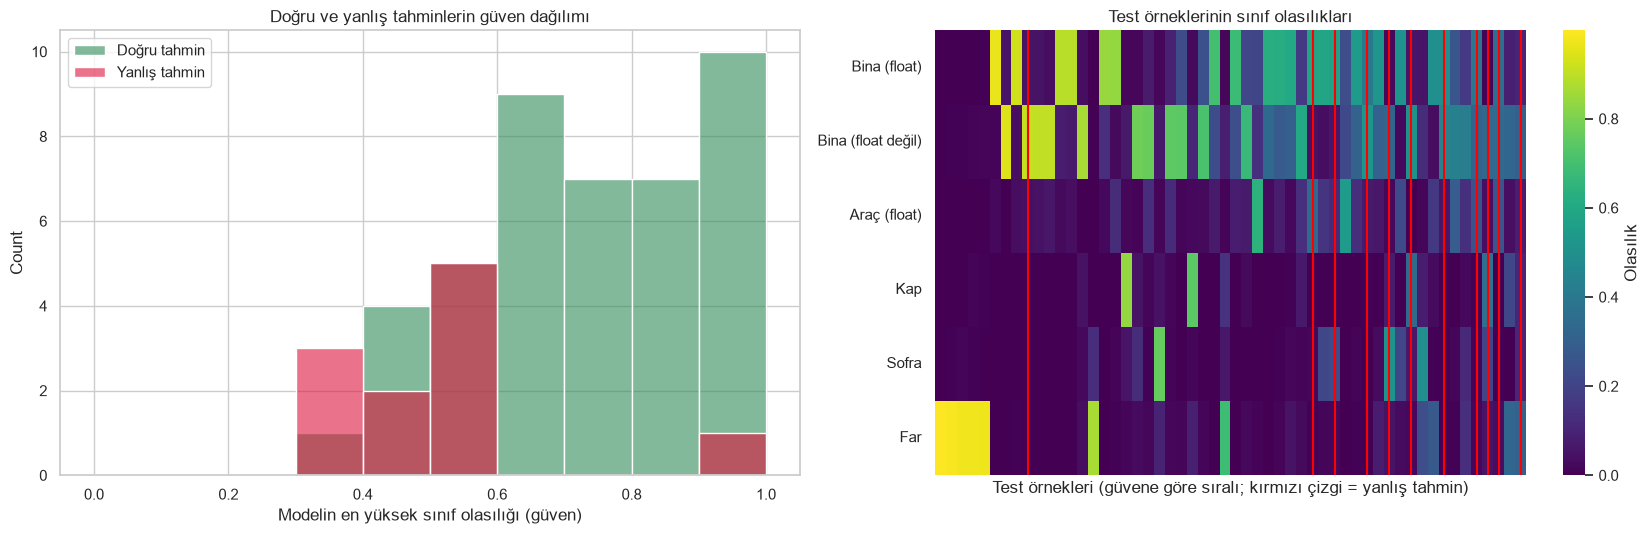

In [35]:
dogru = sonuc["Doğru mu?"] == "✓"
fig, axes = plt.subplots(1, 2, figsize=(17, 5.5))
sns.histplot(sonuc.loc[dogru, "Güven (maks. olasılık)"], bins=10, binrange=(0, 1), color="seagreen",
             label="Doğru tahmin", ax=axes[0], alpha=0.6)
sns.histplot(sonuc.loc[~dogru, "Güven (maks. olasılık)"], bins=10, binrange=(0, 1), color="crimson",
             label="Yanlış tahmin", ax=axes[0], alpha=0.6)
axes[0].set_xlabel("Modelin en yüksek sınıf olasılığı (güven)")
axes[0].set_title("Doğru ve yanlış tahminlerin güven dağılımı")
axes[0].legend()

sira_idx = np.argsort(-y_olasilik.max(axis=1))
sns.heatmap(olasilik_df.iloc[sira_idx].T, cmap="viridis", ax=axes[1], cbar_kws={"label": "Olasılık"},
            xticklabels=False)
yanlis_konum = np.where(~dogru.values[sira_idx])[0]
for x in yanlis_konum:
    axes[1].axvline(x + 0.5, color="red", linewidth=1.5)
axes[1].set_xlabel("Test örnekleri (güvene göre sıralı; kırmızı çizgi = yanlış tahmin)")
axes[1].set_title("Test örneklerinin sınıf olasılıkları")
plt.tight_layout()
plt.show()

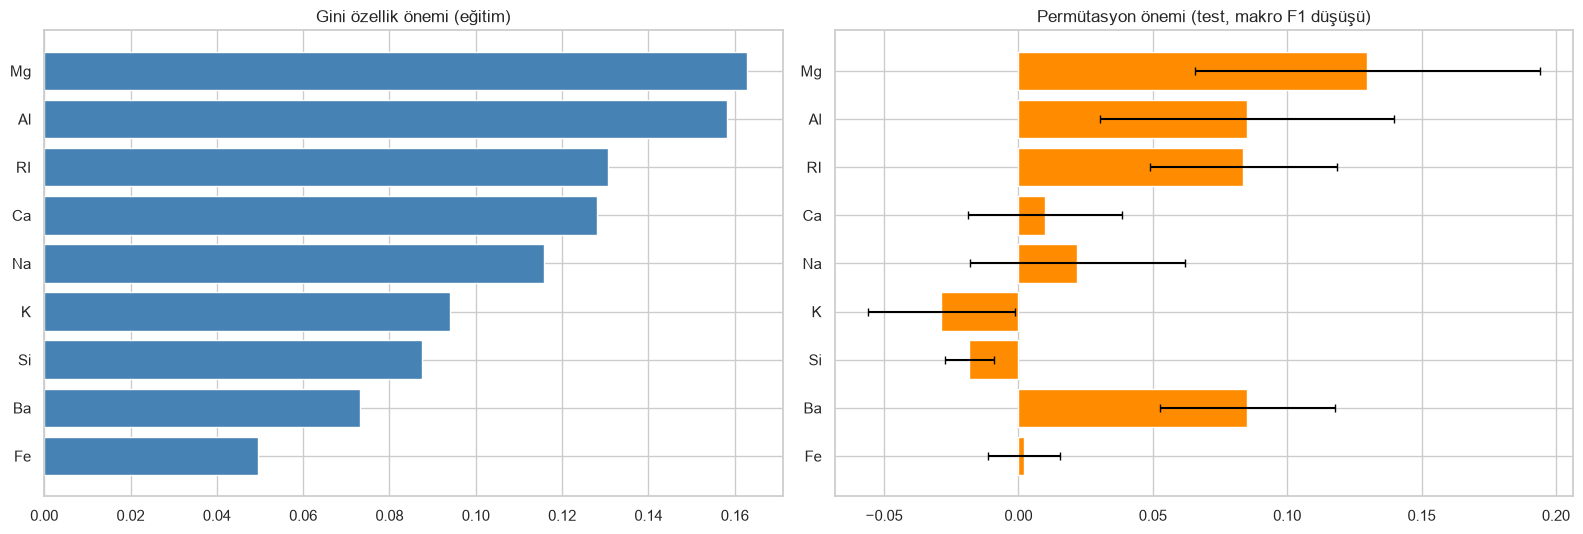

,Gini (ortalama safsızlık azalması),Permütasyon (makro F1 düşüşü),Permütasyon std
Mg,0.1629,0.1298,0.0641
Al,0.1583,0.0850,0.0548
RI,0.1306,0.0836,0.0348
Ca,0.1280,0.0099,0.0286
Na,0.1158,0.0220,0.0398
K,0.0940,-0.0286,0.0272
Si,0.0875,-0.0182,0.0092
Ba,0.0732,0.0852,0.0326
Fe,0.0496,0.0022,0.0133


In [36]:
onem = pd.DataFrame({"Gini (ortalama safsızlık azalması)": model.feature_importances_}, index=OZELLIKLER)
perm = permutation_importance(model, X_test, y_test, n_repeats=30, random_state=42, scoring="f1_macro")
onem["Permütasyon (makro F1 düşüşü)"] = perm.importances_mean
onem["Permütasyon std"] = perm.importances_std
onem = onem.sort_values("Gini (ortalama safsızlık azalması)")

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
axes[0].barh(onem.index, onem["Gini (ortalama safsızlık azalması)"], color="steelblue")
axes[0].set_title("Gini özellik önemi (eğitim)")
axes[1].barh(onem.index, onem["Permütasyon (makro F1 düşüşü)"], xerr=onem["Permütasyon std"], color="darkorange", capsize=3)
axes[1].set_title("Permütasyon önemi (test, makro F1 düşüşü)")
plt.tight_layout()
plt.show()
onem.sort_values("Gini (ortalama safsızlık azalması)", ascending=False)

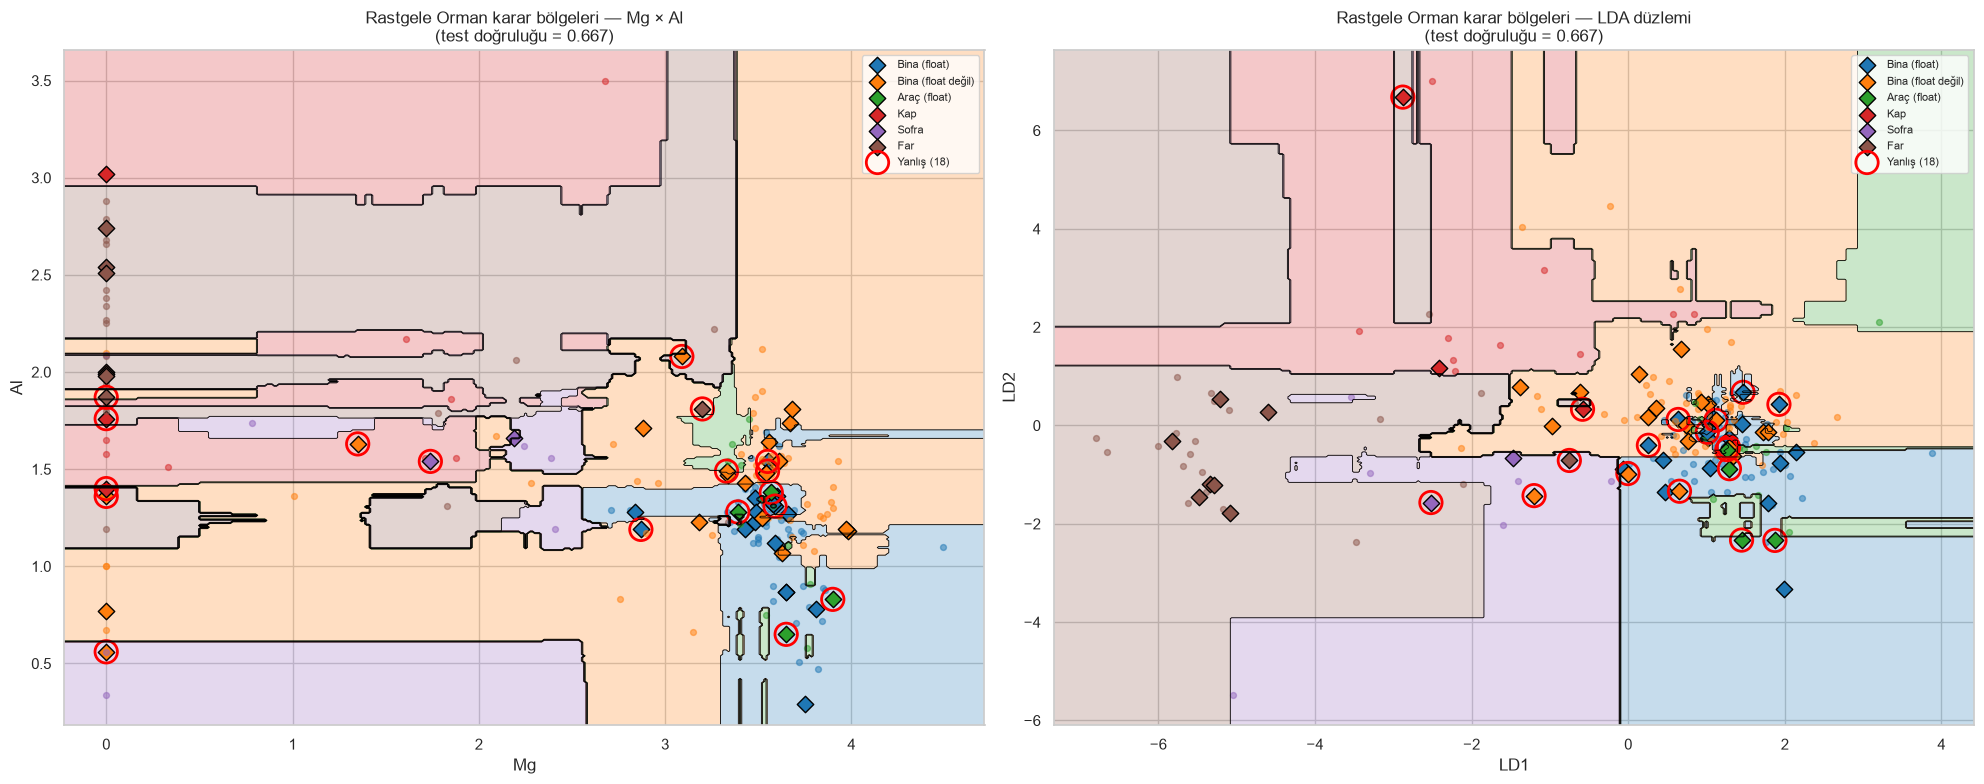

In [37]:
iki = onem["Gini (ortalama safsızlık azalması)"].sort_values(ascending=False).index[:2].tolist()
cmap_bolge = ListedColormap([RENKLER[TUR_ADI[c]] for c in SINIF_SIRASI])
kod = {c: i for i, c in enumerate(SINIF_SIRASI)}

def bolge_ciz(ax, A_egitim, A_test, eksen_adlari, baslik, model2):
    model2.fit(A_egitim, y_egitim)
    pay_x = (A_egitim[:, 0].max() - A_egitim[:, 0].min()) * 0.05
    pay_y = (A_egitim[:, 1].max() - A_egitim[:, 1].min()) * 0.05
    xx, yy = np.meshgrid(np.linspace(A_egitim[:, 0].min() - pay_x, A_egitim[:, 0].max() + pay_x, 400),
                         np.linspace(A_egitim[:, 1].min() - pay_y, A_egitim[:, 1].max() + pay_y, 400))
    zz = pd.Series(model2.predict(np.c_[xx.ravel(), yy.ravel()])).map(kod).values.reshape(xx.shape)
    ax.contourf(xx, yy, zz, levels=np.arange(-0.5, len(SINIF_SIRASI)), cmap=cmap_bolge, alpha=0.25)
    ax.contour(xx, yy, zz, levels=np.arange(0.5, len(SINIF_SIRASI) - 0.5), colors="black", linewidths=0.6)
    for c in SINIF_SIRASI:
        m = y_egitim.values == c
        ax.scatter(A_egitim[m, 0], A_egitim[m, 1], color=RENKLER[TUR_ADI[c]], s=18, alpha=0.5)
        m = y_test.values == c
        ax.scatter(A_test[m, 0], A_test[m, 1], color=RENKLER[TUR_ADI[c]], s=70, marker="D", edgecolor="black",
                   label=TUR_ADI[c])
    tah = model2.predict(A_test)
    yanlis = tah != y_test.values
    ax.scatter(A_test[yanlis, 0], A_test[yanlis, 1], s=260, facecolor="none", edgecolor="red", linewidth=2,
               label=f"Yanlış ({yanlis.sum()})")
    ax.set_xlabel(eksen_adlari[0])
    ax.set_ylabel(eksen_adlari[1])
    ax.set_title(f"{baslik}\n(test doğruluğu = {accuracy_score(y_test, tah):.3f})")
    ax.legend(fontsize=8, loc="best")

fig, axes = plt.subplots(1, 2, figsize=(20, 8))
bolge_ciz(axes[0], X_egitim[iki].values, X_test[iki].values, iki,
          f"Rastgele Orman karar bölgeleri — {iki[0]} × {iki[1]}",
          RandomForestClassifier(n_estimators=500, random_state=42))
lda2 = make_pipeline(StandardScaler(), LinearDiscriminantAnalysis(n_components=2)).fit(X_egitim, y_egitim)
bolge_ciz(axes[1], lda2.transform(X_egitim), lda2.transform(X_test), ["LD1", "LD2"],
          "Rastgele Orman karar bölgeleri — LDA düzlemi", RandomForestClassifier(n_estimators=500, random_state=42))
plt.tight_layout()
plt.show()

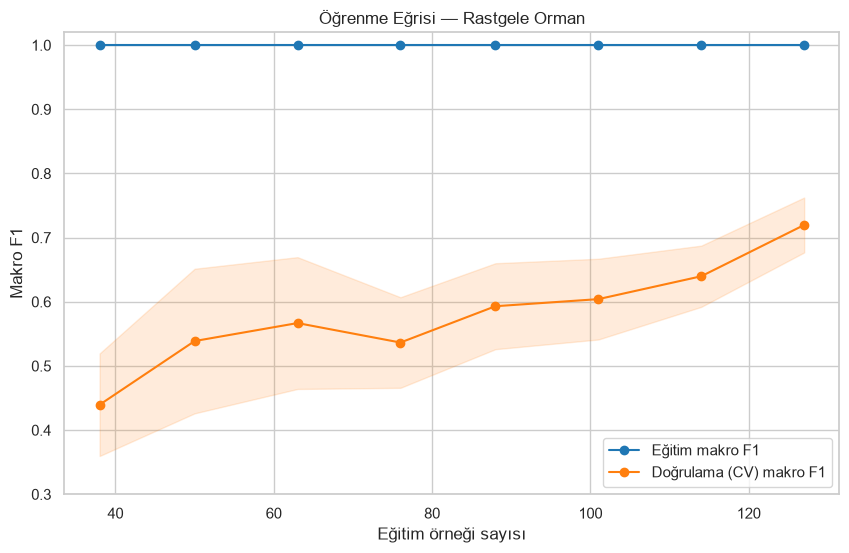

In [38]:
boyut, egitim_skor, dogrulama_skor = learning_curve(
    modeller[EN_IYI], X_egitim, y_egitim, cv=cv, train_sizes=np.linspace(0.3, 1.0, 8), scoring="f1_macro")

fig, ax = plt.subplots(figsize=(10, 6))
for skor, ad, renk in [(egitim_skor, "Eğitim makro F1", "tab:blue"), (dogrulama_skor, "Doğrulama (CV) makro F1", "tab:orange")]:
    ax.plot(boyut, skor.mean(axis=1), "o-", color=renk, label=ad)
    ax.fill_between(boyut, skor.mean(axis=1) - skor.std(axis=1), skor.mean(axis=1) + skor.std(axis=1), color=renk, alpha=0.15)
ax.set_xlabel("Eğitim örneği sayısı")
ax.set_ylabel("Makro F1")
ax.set_ylim(0.3, 1.02)
ax.set_title(f"Öğrenme Eğrisi — {EN_IYI}")
ax.legend(loc="lower right")
plt.show()